# Deep Learning for Daily Store Sales Forecasting

## Objectives

We compare 1D CNN, RNN, and LSTM models using the established four
expanding-window folds and 28-day forecast horizon.

Each network receives the preceding 28 days and predicts the complete
next 28 days in one forward pass. Future calendar features are known
at the forecast origin.

We train a global model across stores, using store identifiers and
store-specific scaling. This allows shared learning while retaining
store information.

For each outer fold, we reserve the final 28 training days as an inner
validation block for epoch selection. We then reinitialize and refit
on the complete outer training data for the selected number of epochs.

Outer validation targets are used only for evaluation. The final holdout
remains unopened.

In [1]:
from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from IPython.display import display

SEED = 42
LOOKBACK = 28

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

COLORS = {
    "purple": "#8055B8",
    "pink": "#DB74A5",
    "lavender": "#B59AD8",
    "rose": "#EDADC8",
    "dark": "#453354",
}

sns.set_theme(
    style="whitegrid",
    palette=list(COLORS.values()),
    rc={
        "figure.figsize": (12, 5),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.25,
    },
)

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.9.1+cpu
Device: cpu


In [2]:
working_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path
        for path in [working_dir, *working_dir.parents]
        if (
            path / "data" / "processed"
            / "retail_forecasting_config.json"
        ).is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate the project configuration.")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results" / "dl_forecasting"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with (
    PROCESSED_DIR / "retail_forecasting_config.json"
).open(encoding="utf-8") as file:
    config = json.load(file)

daily = pd.read_csv(
    PROCESSED_DIR / "retail_daily_store_dev.csv",
    parse_dates=["date"],
)

cv_schedule = pd.read_csv(
    PROCESSED_DIR / "retail_cv_schedule.csv",
    parse_dates=["train_end", "validation_start", "validation_end"],
)

HORIZON = int(config["forecast_horizon_days"])
TEST_START = pd.Timestamp(config["test_start"])

assert HORIZON == 28
assert not daily.duplicated(["store_id", "date"]).any()
assert daily["date"].max() < TEST_START

store_series = {
    int(store_id): (
        group.set_index("date")["y"]
        .sort_index()
        .asfreq("D")
    )
    for store_id, group in daily.groupby("store_id")
}

STORE_IDS = sorted(store_series)
STORE_TO_INDEX = {
    store_id: index for index, store_id in enumerate(STORE_IDS)
}

display(cv_schedule)

,fold,train_end,validation_start,validation_end,horizon_days
0,1,2024-05-09,2024-05-10,2024-06-06,28
1,2,2024-06-06,2024-06-07,2024-07-04,28
2,3,2024-07-04,2024-07-05,2024-08-01,28
3,4,2024-08-01,2024-08-02,2024-08-29,28


## 1. Window Construction and Temporal Boundaries

Training windows contain 28 historical days followed by 28 target days.
Both parts must lie within the relevant training interval.

We exclude windows containing missing sales observations.
We never replace missing targets with synthetic labels.

For each store, we divide sales by its mean observed amount calculated
from the relevant fitting interval. Inner validation scaling uses only
the inner training interval. Final outer-fold refitting recalculates
scales using the complete outer training interval.

Historical inputs contain scaled sales and weekday indicators.
Future inputs contain weekday indicators for the 28 target dates.

In [3]:
def weekday_features(dates):
    dates = pd.DatetimeIndex(dates)
    return np.eye(7, dtype=np.float32)[dates.dayofweek]


def estimate_store_scales(cutoff):
    scales = {}

    for store_id, series in store_series.items():
        observed = series.loc[:cutoff].dropna()

        if (
            observed.empty
            or not np.isfinite(observed.to_numpy()).all()
        ):
            raise ValueError("Invalid observations for scaling.")

        scale = float(observed.mean())

        if scale <= 0:
            raise ValueError("Scaling requires a positive mean.")

        scales[store_id] = scale

    return scales


def build_training_windows(cutoff, scales):
    histories, calendars, store_indices, targets = [], [], [], []
    metadata = []

    for store_id, full_series in store_series.items():
        series = full_series.loc[:cutoff]
        values = series.to_numpy(dtype=float)

        for target_start in range(
            LOOKBACK, len(series) - HORIZON + 1
        ):
            past = values[target_start - LOOKBACK:target_start]
            future = values[target_start:target_start + HORIZON]

            if not (
                np.isfinite(past).all()
                and np.isfinite(future).all()
            ):
                continue

            past_dates = series.index[
                target_start - LOOKBACK:target_start
            ]
            future_dates = series.index[
                target_start:target_start + HORIZON
            ]

            histories.append(np.column_stack([
                past / scales[store_id],
                weekday_features(past_dates),
            ]))

            calendars.append(weekday_features(future_dates))
            store_indices.append(STORE_TO_INDEX[store_id])
            targets.append(future / scales[store_id])

            metadata.append({
                "store_id": store_id,
                "origin": past_dates[-1],
                "target_start": future_dates[0],
                "target_end": future_dates[-1],
            })

    if not histories:
        raise ValueError("No complete training windows.")

    arrays = (
        np.asarray(histories, dtype=np.float32),
        np.asarray(calendars, dtype=np.float32),
        np.asarray(store_indices, dtype=np.int64),
        np.asarray(targets, dtype=np.float32),
    )

    return arrays, pd.DataFrame(metadata)


def build_forecast_window(store_id, origin, scales):
    history = store_series[store_id].loc[:origin].tail(LOOKBACK)

    if (
        len(history) != LOOKBACK
        or history.index[-1] != origin
        or not np.isfinite(history.to_numpy()).all()
    ):
        raise ValueError("Incomplete forecast history.")

    future_dates = pd.date_range(
        origin + pd.Timedelta(days=1),
        periods=HORIZON,
        freq="D",
    )

    past_input = np.column_stack([
        history.to_numpy() / scales[store_id],
        weekday_features(history.index),
    ]).astype(np.float32)

    return (
        past_input,
        weekday_features(future_dates),
        STORE_TO_INDEX[store_id],
        future_dates,
    )

In [4]:
dl_fold_setup = {}
audit_rows = []

for fold in cv_schedule.itertuples(index=False):
    outer_end = pd.Timestamp(fold.train_end)
    inner_origin = outer_end - pd.Timedelta(days=HORIZON)

    assert fold.validation_start == (
        outer_end + pd.Timedelta(days=1)
    )
    assert fold.validation_end < TEST_START

    inner_scales = estimate_store_scales(inner_origin)
    inner_arrays, inner_metadata = build_training_windows(
        inner_origin, inner_scales
    )

    assert inner_metadata["target_end"].max() <= inner_origin

    outer_scales = estimate_store_scales(outer_end)
    outer_arrays, outer_metadata = build_training_windows(
        outer_end, outer_scales
    )

    assert outer_metadata["target_end"].max() <= outer_end

    for store_id in STORE_IDS:
        _, _, _, inner_dates = build_forecast_window(
            store_id, inner_origin, inner_scales
        )
        _, _, _, outer_dates = build_forecast_window(
            store_id, outer_end, outer_scales
        )

        inner_actual = store_series[store_id].reindex(inner_dates)
        outer_actual = store_series[store_id].reindex(outer_dates)

        assert inner_dates[-1] == outer_end
        assert outer_dates[0] == fold.validation_start
        assert outer_dates[-1] == fold.validation_end

        if not (
            np.isfinite(inner_actual.to_numpy()).all()
            and np.isfinite(outer_actual.to_numpy()).all()
        ):
            raise ValueError("Missing inner or outer validation targets.")

        audit_rows.append({
            "fold": int(fold.fold),
            "store_id": store_id,
            "inner_training_windows": int(
                inner_metadata["store_id"].eq(store_id).sum()
            ),
            "outer_training_windows": int(
                outer_metadata["store_id"].eq(store_id).sum()
            ),
            "inner_origin": inner_origin,
            "outer_origin": outer_end,
        })

    dl_fold_setup[int(fold.fold)] = {
        "inner_origin": inner_origin,
        "outer_origin": outer_end,
        "inner_scales": inner_scales,
        "outer_scales": outer_scales,
        "inner_arrays": inner_arrays,
        "outer_arrays": outer_arrays,
    }

display(pd.DataFrame(audit_rows))
print("All inner/outer temporal checks passed.")

,fold,store_id,inner_training_windows,outer_training_windows,inner_origin,outer_origin
0,1,1,538,566,2024-04-11,2024-05-09
1,1,2,538,566,2024-04-11,2024-05-09
2,1,3,488,516,2024-04-11,2024-05-09
3,1,4,66,94,2024-04-11,2024-05-09
4,2,1,566,594,2024-05-09,2024-06-06
5,2,2,566,594,2024-05-09,2024-06-06
6,2,3,516,544,2024-05-09,2024-06-06
7,2,4,94,122,2024-05-09,2024-06-06
8,3,1,594,622,2024-06-06,2024-07-04
9,3,2,594,622,2024-06-06,2024-07-04


All inner/outer temporal checks passed.


## 2. Neural Architectures and Training Protocol

We compare CNN, RNN, and LSTM encoders with hidden widths 16 and 32.
Each model combines the historical sequence, store embedding, and future
weekday indicators to predict all 28 days simultaneously.

The network predicts a correction to the last observed weekly pattern.
The correction head starts at zero, so the initial forecast equals
seasonal naive. This is an architectural choice shared by all candidates.

We optimize mean squared error on store-scaled targets. Training windows
are pooled across stores, so stores with more complete windows contribute
more training examples. Model selection uses equally weighted store WAPE.

For each fold, inner-validation WAPE selects the epoch count.
We then reinitialize the model and train on the complete outer training
interval for that many epochs. Outer validation never controls training.

We use a fixed seed, gradient clipping, and a maximum of 100 epochs.
Results from one seed do not measure neural initialization variability.

In [5]:
from time import perf_counter

# Small networks can be slower with excessive CPU threading.
torch.set_num_threads(min(4, torch.get_num_threads()))

DL_CANDIDATES = [
    {"name": f"{architecture.upper()} width={width}",
     "architecture": architecture, "width": width}
    for architecture in ["cnn", "rnn", "lstm"]
    for width in [16, 32]
]

MAX_EPOCHS = 100
PATIENCE = 12
BATCH_SIZE = 128
LEARNING_RATE = 1e-3


def reset_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class NeuralForecaster(nn.Module):
    def __init__(self, architecture, width):
        super().__init__()
        self.architecture = architecture

        if architecture == "cnn":
            self.encoder = nn.Sequential(
                nn.Conv1d(8, width, kernel_size=3, padding=1),
                nn.ReLU(),
                nn.Conv1d(width, width, kernel_size=3, padding=1),
                nn.ReLU(),
                nn.Flatten(),
            )
            encoded_size = width * LOOKBACK

        elif architecture == "rnn":
            self.encoder = nn.RNN(
                input_size=8,
                hidden_size=width,
                batch_first=True,
                nonlinearity="tanh",
            )
            encoded_size = width

        elif architecture == "lstm":
            self.encoder = nn.LSTM(
                input_size=8,
                hidden_size=width,
                batch_first=True,
            )
            encoded_size = width
        else:
            raise ValueError("Unknown architecture.")

        self.store_embedding = nn.Embedding(len(STORE_IDS), 4)

        self.head = nn.Sequential(
            nn.Linear(encoded_size + 4 + HORIZON * 7, width),
            nn.ReLU(),
            nn.Linear(width, HORIZON),
        )

        nn.init.zeros_(self.head[-1].weight)
        nn.init.zeros_(self.head[-1].bias)

    def forward(self, history, future_calendar, store_index):
        if self.architecture == "cnn":
            encoded = self.encoder(history.transpose(1, 2))
        else:
            sequence, _ = self.encoder(history)
            encoded = sequence[:, -1, :]

        combined = torch.cat([
            encoded,
            self.store_embedding(store_index),
            future_calendar.flatten(start_dim=1),
        ], dim=1)

        weekly_baseline = history[:, -7:, 0].repeat(
            1, (HORIZON + 6) // 7
        )[:, :HORIZON]

        return weekly_baseline + self.head(combined)

In [6]:
def make_loader(arrays, seed):
    dataset = TensorDataset(
        torch.from_numpy(arrays[0]),
        torch.from_numpy(arrays[1]),
        torch.from_numpy(arrays[2]),
        torch.from_numpy(arrays[3]),
    )
    generator = torch.Generator().manual_seed(seed)

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
    )


def train_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    total_examples = 0

    for history, calendar, store_index, target in loader:
        history = history.to(DEVICE)
        calendar = calendar.to(DEVICE)
        store_index = store_index.to(DEVICE)
        target = target.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        prediction = model(history, calendar, store_index)
        loss = nn.functional.mse_loss(prediction, target)

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss.")

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item() * len(target)
        total_examples += len(target)

    return total_loss / total_examples


@torch.no_grad()
def forecast_stores(model, origin, scales):
    model.eval()
    forecasts = {}

    for store_id in STORE_IDS:
        past, calendar, index, dates = build_forecast_window(
            store_id, origin, scales
        )

        prediction = model(
            torch.from_numpy(past[None]).to(DEVICE),
            torch.from_numpy(calendar[None]).to(DEVICE),
            torch.tensor([index], dtype=torch.long, device=DEVICE),
        ).cpu().numpy()[0] * scales[store_id]

        if not np.isfinite(prediction).all():
            raise RuntimeError("Non-finite forecast.")

        forecasts[store_id] = (dates, prediction)

    return forecasts


def mean_inner_wape(model, origin, scales):
    forecasts = forecast_stores(model, origin, scales)
    errors = []

    for store_id, (dates, prediction) in forecasts.items():
        actual = store_series[store_id].reindex(dates).to_numpy()
        denominator = np.abs(actual).sum()

        if not np.isfinite(actual).all() or denominator <= 0:
            raise ValueError("Invalid inner-validation targets.")

        errors.append(
            100 * np.abs(prediction - actual).sum() / denominator
        )

    return float(np.mean(errors))


def select_epoch_count(spec, setup, seed):
    reset_seed(seed)
    model = NeuralForecaster(
        spec["architecture"], spec["width"]
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4
    )
    loader = make_loader(setup["inner_arrays"], seed)

    # Epoch zero is the seasonal-naive initialization.
    best_wape = mean_inner_wape(
        model, setup["inner_origin"], setup["inner_scales"]
    )
    best_epoch = 0
    stale_epochs = 0
    history_rows = [{
        "epoch": 0, "train_MSE": np.nan, "inner_WAPE_pct": best_wape
    }]

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss = train_epoch(model, loader, optimizer)
        inner_wape = mean_inner_wape(
            model, setup["inner_origin"], setup["inner_scales"]
        )

        history_rows.append({
            "epoch": epoch,
            "train_MSE": train_loss,
            "inner_WAPE_pct": inner_wape,
        })

        if inner_wape < best_wape - 1e-4:
            best_wape = inner_wape
            best_epoch = epoch
            stale_epochs = 0
        else:
            stale_epochs += 1

        if stale_epochs >= PATIENCE:
            break

    return best_epoch, best_wape, history_rows


def refit_outer_model(spec, setup, epochs, seed):
    reset_seed(seed)
    model = NeuralForecaster(
        spec["architecture"], spec["width"]
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4
    )
    loader = make_loader(setup["outer_arrays"], seed)

    for _ in range(epochs):
        train_epoch(model, loader, optimizer)

    return model

In [7]:
dl_score_rows = []
dl_prediction_parts = []
dl_history_rows = []
dl_selection_rows = []

for candidate_number, spec in enumerate(DL_CANDIDATES, start=1):
    print(f"\n{candidate_number}/{len(DL_CANDIDATES)}: {spec['name']}")

    for fold, setup in dl_fold_setup.items():
        started = perf_counter()
        run_seed = SEED + fold

        epochs, inner_wape, history_rows = select_epoch_count(
            spec, setup, run_seed
        )

        model = refit_outer_model(
            spec, setup, epochs, run_seed
        )
        forecasts = forecast_stores(
            model, setup["outer_origin"], setup["outer_scales"]
        )

        for store_id, (dates, prediction) in forecasts.items():
            actual = store_series[store_id].reindex(dates).to_numpy()
            error = prediction - actual
            denominator = np.abs(actual).sum()

            assert dates.max() < TEST_START
            assert np.isfinite(actual).all()
            assert denominator > 0

            dl_score_rows.append({
                "model": spec["name"],
                "fold": fold,
                "store_id": store_id,
                "MAE": np.abs(error).mean(),
                "RMSE": np.sqrt(np.mean(error ** 2)),
                "WAPE_pct": 100 * np.abs(error).sum() / denominator,
                "bias_pct": 100 * error.sum() / denominator,
            })

            dl_prediction_parts.append(pd.DataFrame({
                "model": spec["name"],
                "fold": fold,
                "store_id": store_id,
                "date": dates,
                "actual": actual,
                "prediction": prediction,
            }))

        dl_history_rows.extend([
            {"model": spec["name"], "fold": fold, **row}
            for row in history_rows
        ])

        dl_selection_rows.append({
            "model": spec["name"],
            "fold": fold,
            "selected_epochs": epochs,
            "best_inner_WAPE_pct": inner_wape,
            "seconds": perf_counter() - started,
        })

        checkpoint_path = RESULTS_DIR / (
            f"{spec['architecture']}_w{spec['width']}_fold{fold}.pt"
        )
        torch.save({
            "state_dict": {
                key: value.detach().cpu()
                for key, value in model.state_dict().items()
            },
            "spec": spec,
            "selected_epochs": epochs,
            "store_ids": STORE_IDS,
            "scales": setup["outer_scales"],
            "lookback": LOOKBACK,
            "horizon": HORIZON,
        }, checkpoint_path)

        pd.DataFrame(dl_score_rows).to_csv(
            RESULTS_DIR / "dl_cv_scores.csv", index=False
        )
        pd.concat(dl_prediction_parts, ignore_index=True).to_csv(
            RESULTS_DIR / "dl_cv_predictions.csv", index=False
        )
        pd.DataFrame(dl_history_rows).to_csv(
            RESULTS_DIR / "dl_training_history.csv", index=False
        )
        pd.DataFrame(dl_selection_rows).to_csv(
            RESULTS_DIR / "dl_epoch_selection.csv", index=False
        )

        print(
            f"  Fold {fold}: epochs={epochs}, "
            f"inner WAPE={inner_wape:.2f}%, "
            f"time={perf_counter() - started:.1f}s"
        )

        del model

dl_scores = pd.DataFrame(dl_score_rows)
dl_predictions = pd.concat(dl_prediction_parts, ignore_index=True)
dl_training_history = pd.DataFrame(dl_history_rows)
dl_epoch_selection = pd.DataFrame(dl_selection_rows)

dl_summary = (
    dl_scores.groupby("model")
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        worst_WAPE_pct=("WAPE_pct", "max"),
        mean_bias_pct=("bias_pct", "mean"),
        evaluated_store_folds=("WAPE_pct", "count"),
    )
    .sort_values("mean_WAPE_pct")
)

assert dl_summary["evaluated_store_folds"].eq(
    len(cv_schedule) * len(STORE_IDS)
).all()

display(dl_summary)
display(dl_epoch_selection)


1/6: CNN width=16
  Fold 1: epochs=17, inner WAPE=12.04%, time=11.4s
  Fold 2: epochs=95, inner WAPE=15.48%, time=26.2s
  Fold 3: epochs=0, inner WAPE=4.79%, time=2.4s
  Fold 4: epochs=5, inner WAPE=4.12%, time=3.3s

2/6: CNN width=32
  Fold 1: epochs=8, inner WAPE=12.21%, time=4.0s
  Fold 2: epochs=56, inner WAPE=15.00%, time=17.4s
  Fold 3: epochs=4, inner WAPE=4.76%, time=3.2s
  Fold 4: epochs=7, inner WAPE=4.04%, time=4.3s

3/6: RNN width=16
  Fold 1: epochs=17, inner WAPE=12.13%, time=7.4s
  Fold 2: epochs=7, inner WAPE=23.87%, time=4.5s
  Fold 3: epochs=0, inner WAPE=4.79%, time=2.2s
  Fold 4: epochs=4, inner WAPE=4.31%, time=4.1s

4/6: RNN width=32
  Fold 1: epochs=6, inner WAPE=12.43%, time=4.2s
  Fold 2: epochs=99, inner WAPE=19.07%, time=35.5s
  Fold 3: epochs=4, inner WAPE=4.65%, time=4.1s
  Fold 4: epochs=4, inner WAPE=4.25%, time=4.3s

5/6: LSTM width=16
  Fold 1: epochs=46, inner WAPE=11.59%, time=13.3s
  Fold 2: epochs=14, inner WAPE=23.16%, time=5.8s
  Fold 3: epochs=0

,mean_WAPE_pct,worst_WAPE_pct,mean_bias_pct,evaluated_store_folds
model,,,,
LSTM width=16,9.697029,28.017510,2.889683,16
RNN width=16,10.050019,27.654966,1.689235,16
RNN width=32,10.251950,26.398800,1.810551,16
CNN width=32,10.498156,26.953774,1.202349,16
CNN width=16,10.727530,25.899273,0.322773,16
LSTM width=32,10.928079,27.143757,-0.603089,16


,model,fold,selected_epochs,best_inner_WAPE_pct,seconds
0,CNN width=16,1,17,12.038051,11.338233
1,CNN width=16,2,95,15.484240,26.135868
2,CNN width=16,3,0,4.792604,2.432442
3,CNN width=16,4,5,4.119737,3.243070
4,CNN width=32,1,8,12.214669,3.976298
5,CNN width=32,2,56,15.001312,17.424878
6,CNN width=32,3,4,4.764521,3.226230
7,CNN width=32,4,7,4.041317,4.273832
8,RNN width=16,1,17,12.129218,7.392387
9,RNN width=16,2,7,23.869779,4.433228


## 3. Training Diagnostics

We inspect the inner-validation WAPE trajectories and the selected training
duration for each architecture and fold. Epoch zero represents the initial
seasonal-naive forecast before any neural correction is learned.

The inner validation determines the number of epochs. The outer validation
remains reserved for comparing forecasting performance. A lower inner-validation
error does not necessarily imply better outer-validation performance.

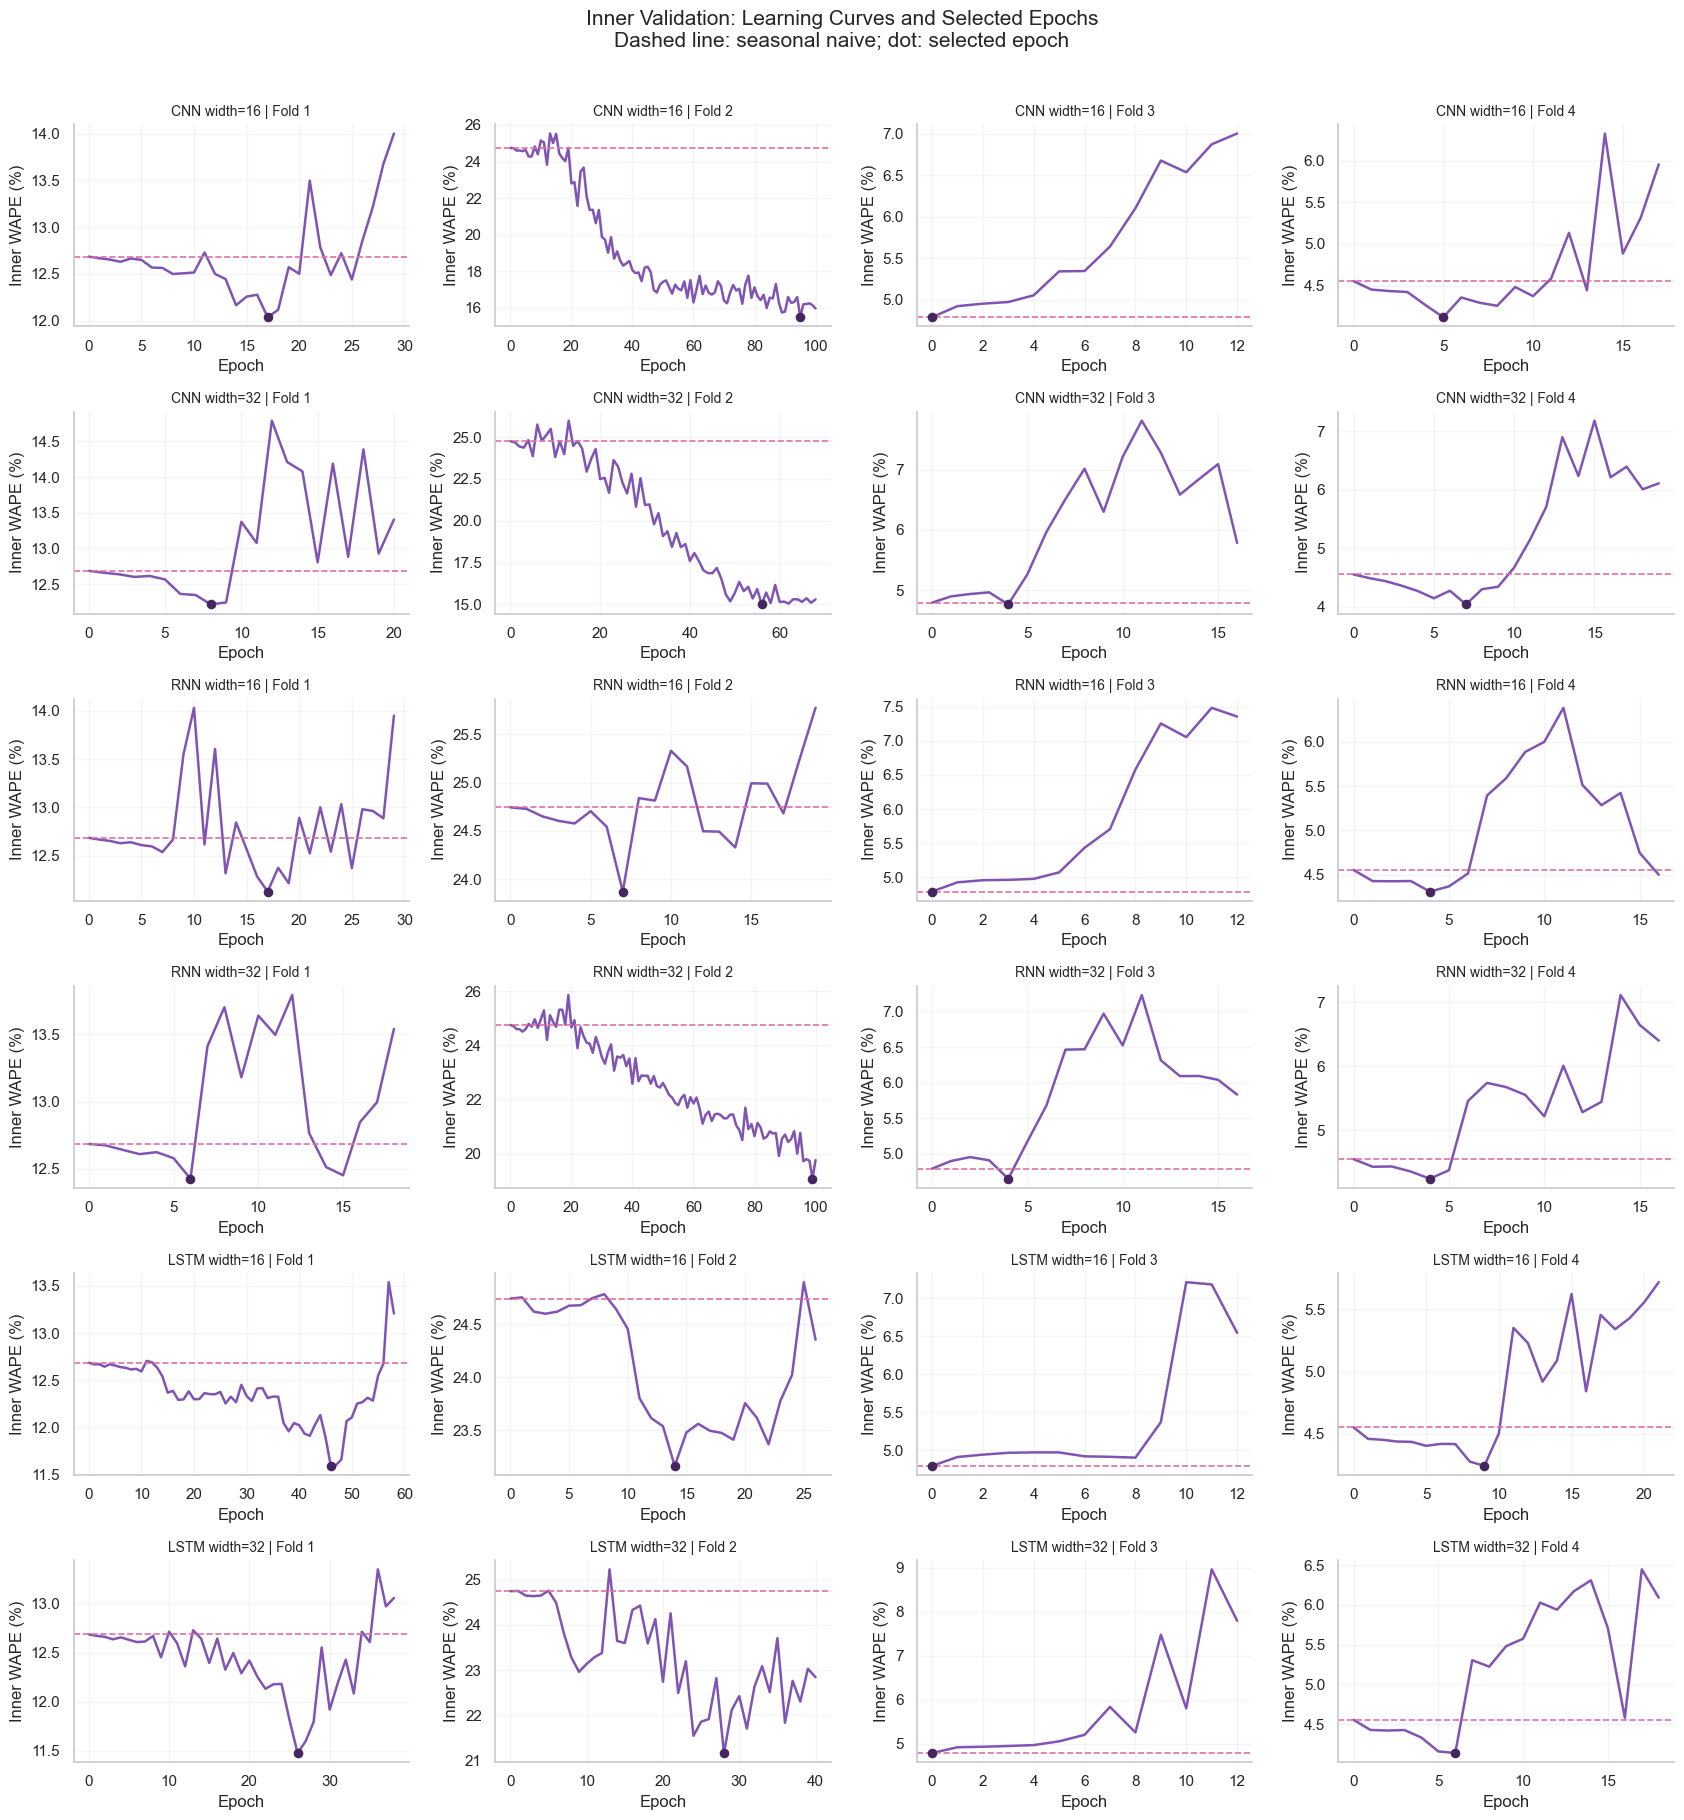

In [9]:
model_names = [spec["name"] for spec in DL_CANDIDATES]
fold_ids = sorted(dl_training_history["fold"].unique())

fig, axes = plt.subplots(
    len(model_names),
    len(fold_ids),
    figsize=(17, 18),
    squeeze=False,
)

for row, model_name in enumerate(model_names):
    for col, fold_id in enumerate(fold_ids):
        ax = axes[row, col]

        history = (
            dl_training_history.loc[
                (dl_training_history["model"] == model_name)
                & (dl_training_history["fold"] == fold_id)
            ]
            .sort_values("epoch")
        )

        selection = dl_epoch_selection.loc[
            (dl_epoch_selection["model"] == model_name)
            & (dl_epoch_selection["fold"] == fold_id)
        ].iloc[0]

        baseline = history.loc[
            history["epoch"] == 0, "inner_WAPE_pct"
        ].iloc[0]

        ax.plot(
            history["epoch"],
            history["inner_WAPE_pct"],
            color="#8054B3",
            linewidth=1.8,
        )

        ax.axhline(
            baseline,
            color="#DB72A3",
            linestyle="--",
            linewidth=1.2,
        )

        ax.scatter(
            selection["selected_epochs"],
            selection["best_inner_WAPE_pct"],
            color="#45265F",
            s=35,
            zorder=3,
        )

        ax.set_title(f"{model_name} | Fold {fold_id}", fontsize=10)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Inner WAPE (%)")
        ax.grid(alpha=0.2)

fig.suptitle(
    "Inner Validation: Learning Curves and Selected Epochs\n"
    "Dashed line: seasonal naive; dot: selected epoch",
    fontsize=15,
    y=1.01,
)

plt.tight_layout()
plt.show()

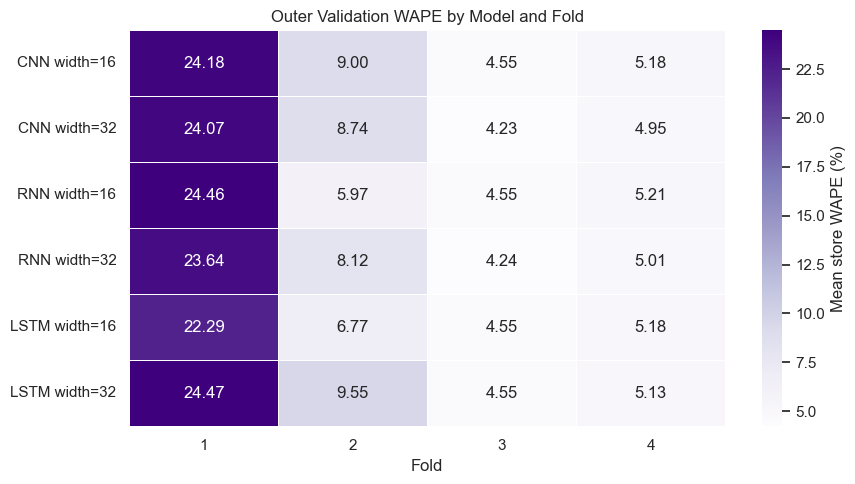

fold,1,2,3,4
model,,,,
CNN width=16,24.176,9.001,4.553,5.181
CNN width=32,24.068,8.743,4.230,4.952
RNN width=16,24.458,5.974,4.553,5.215
RNN width=32,23.641,8.124,4.235,5.007
LSTM width=16,22.289,6.769,4.553,5.177
LSTM width=32,24.474,9.552,4.553,5.134


In [10]:
fold_wape = (
    dl_scores.groupby(["model", "fold"])["WAPE_pct"]
    .mean()
    .unstack("fold")
    .reindex(model_names)
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.heatmap(
    fold_wape,
    annot=True,
    fmt=".2f",
    cmap="Purples",
    linewidths=0.5,
    cbar_kws={"label": "Mean store WAPE (%)"},
    ax=ax,
)

ax.set_title("Outer Validation WAPE by Model and Fold")
ax.set_xlabel("Fold")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

display(fold_wape.round(3))

In [11]:
classical_scores = pd.read_csv(
    PROJECT_ROOT
    / "results"
    / "classical_forecasting"
    / "classical_cv_scores.csv"
)

# Find the seasonal-naive baseline using its saved model name.
baseline_names = [
    name
    for name in classical_scores["model"].unique()
    if "seasonal" in name.lower() and "naive" in name.lower()
]

assert len(baseline_names) == 1, (
    f"Expected one seasonal-naive baseline, found: {baseline_names}"
)

baseline_name = baseline_names[0]

baseline_scores = classical_scores.loc[
    classical_scores["model"] == baseline_name
].copy()

assert not baseline_scores.duplicated(["fold", "store_id"]).any()

paired_comparison = dl_scores.merge(
    baseline_scores[["fold", "store_id", "WAPE_pct"]].rename(
        columns={"WAPE_pct": "baseline_WAPE_pct"}
    ),
    on=["fold", "store_id"],
    how="left",
    validate="many_to_one",
)

assert paired_comparison["baseline_WAPE_pct"].notna().all()

# Positive values indicate improvement over seasonal naive.
paired_comparison["improvement_pp"] = (
    paired_comparison["baseline_WAPE_pct"]
    - paired_comparison["WAPE_pct"]
)

baseline_comparison = (
    paired_comparison.groupby("model")
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        mean_improvement_pp=("improvement_pp", "mean"),
        wins=("improvement_pp", lambda x: int((x > 1e-4).sum())),
        ties=("improvement_pp", lambda x: int((x.abs() <= 1e-4).sum())),
        losses=("improvement_pp", lambda x: int((x < -1e-4).sum())),
    )
    .sort_values("mean_WAPE_pct")
)

display(baseline_comparison.round(3))

fold_comparison = pd.concat(
    [
        fold_wape,
        baseline_scores.groupby("fold")["WAPE_pct"]
        .mean()
        .to_frame()
        .T
        .rename(index={"WAPE_pct": baseline_name}),
    ]
)

display(fold_comparison.round(3))

dl_summary.to_csv(RESULTS_DIR / "dl_cv_summary.csv")
baseline_comparison.to_csv(
    RESULTS_DIR / "dl_baseline_comparison.csv"
)
paired_comparison.to_csv(
    RESULTS_DIR / "dl_paired_baseline_scores.csv",
    index=False,
)

,mean_WAPE_pct,mean_improvement_pp,wins,ties,losses
model,,,,,
LSTM width=16,9.697,0.075,3,4,9
RNN width=16,10.050,-0.278,4,4,8
RNN width=32,10.252,-0.480,7,0,9
CNN width=32,10.498,-0.726,6,0,10
CNN width=16,10.728,-0.955,6,4,6
LSTM width=32,10.928,-1.156,5,4,7


fold,1,2,3,4
CNN width=16,24.176,9.001,4.553,5.181
CNN width=32,24.068,8.743,4.230,4.952
RNN width=16,24.458,5.974,4.553,5.215
RNN width=32,23.641,8.124,4.235,5.007
LSTM width=16,22.289,6.769,4.553,5.177
LSTM width=32,24.474,9.552,4.553,5.134
Seasonal naive,24.744,4.793,4.553,5.000


## 4. Preliminary Findings

Among the six neural candidates, LSTM with hidden width 16 achieves the
lowest mean outer-validation WAPE (9.697%). Its improvement over the
seasonal-naive baseline (9.772%) is only about 0.075 percentage points.
We therefore do not interpret this difference as convincing evidence
of a reliable neural advantage.

Performance varies substantially across validation periods. All neural
candidates have their highest fold-average WAPE in the first fold.
LSTM with width 16 performs best on that fold, but no candidate wins
on every fold.

For four candidates, the third fold selects zero training epochs.
Their forecasts therefore retain the initial seasonal-naive predictions.
This shows that the learned corrections do not consistently improve
the inner-validation objective.

These results describe one random seed and four chronological folds.
They do not establish statistical significance or performance outside
the evaluated periods. Prophet and Ridge currently achieve lower
mean cross-validation WAPE than these neural candidates.

The paired comparison further limits our interpretation of the best neural
result. LSTM with width 16 improves on seasonal naive in only 3 of the
16 store–fold combinations, ties in 4, and performs worse in 9.
Its small average advantage therefore does not represent consistent
improvement across stores and periods.